# Создание box-plot диграммы для проверки существования выборосов в датасете

In [2]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt


Регион 33
Количество наблюдений: 41361
Медиана: 838.00 МВт*ч
Q1: 749.00
Q3: 932.00
IQR: 183.00
Границы: [474.50; 1206.50]
Потенциальных выбросов: 9

Регион 57
Количество наблюдений: 41336
Медиана: 2701.00 МВт*ч
Q1: 2491.00
Q3: 2963.00
IQR: 472.00
Границы: [1783.00; 3671.00]
Потенциальных выбросов: 1

Регион 71
Количество наблюдений: 41365
Медиана: 10138.00 МВт*ч
Q1: 9462.00
Q3: 11132.00
IQR: 1670.00
Границы: [6957.00; 13637.00]
Потенциальных выбросов: 0

Регион 75
Количество наблюдений: 17535
Медиана: 4268.00 МВт*ч
Q1: 3980.00
Q3: 4543.00
IQR: 563.00
Границы: [3135.50; 5387.50]
Потенциальных выбросов: 52

Регион 94
Количество наблюдений: 41369
Медиана: 1098.00 МВт*ч
Q1: 985.00
Q3: 1214.00
IQR: 229.00
Границы: [641.50; 1557.50]
Потенциальных выбросов: 19


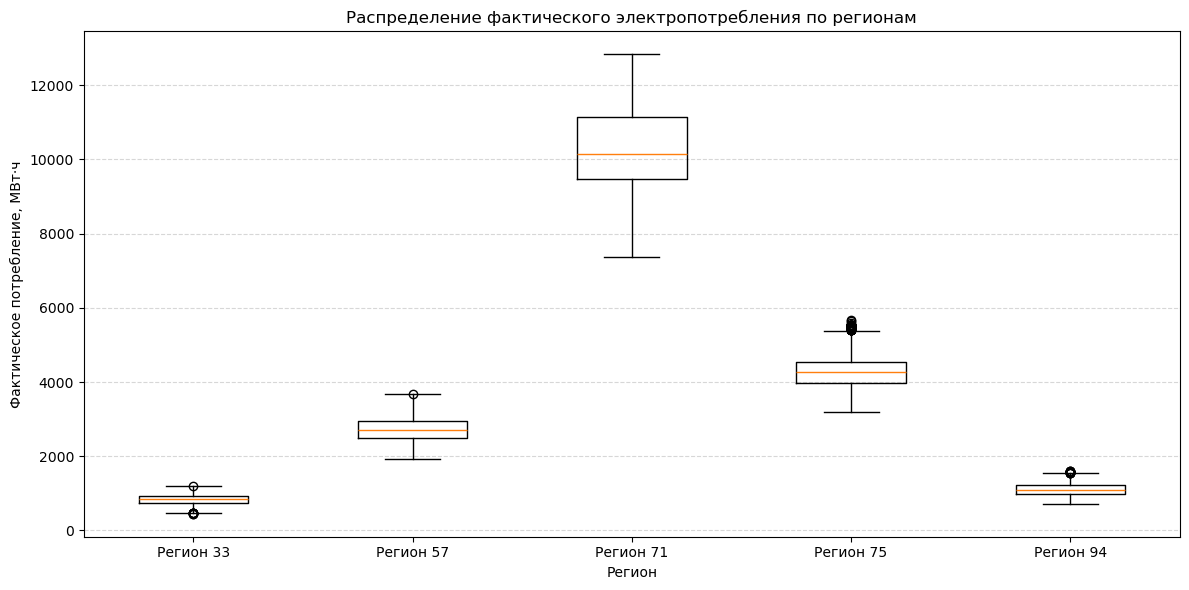


Выбросы сохранены в potential_outliers.csv


In [7]:
# Папка с CSV-файлами относительно корня проекта
DATA_DIR = "../../datasets"

# Столбец с фактическим электропотреблением
TARGET_COLUMN = "actual_consumption"


def parse_consumption(value):
    """Преобразует значения вроде '4 076 МВт*ч' в число 4076."""
    if pd.isna(value):
        return None

    value = str(value).replace("\xa0", "").replace(" ", "")
    value = value.replace("МВт*ч", "").replace("МВт·ч", "")

    try:
        return float(value.replace(",", "."))
    except ValueError:
        return None


def main():
    files = glob.glob(
        os.path.join(DATA_DIR, "electricity_*.csv")
    )

    if not files:
        raise FileNotFoundError(
            f"CSV-файлы не найдены в папке: {os.path.abspath(DATA_DIR)}"
        )

    data_by_region = {}
    all_outliers = []

    for file in files:
        # Определяем код региона из имени файла
        region = os.path.basename(file).replace(
            "electricity_", ""
        ).replace(".csv", "")

        try:
            df = pd.read_csv(file, encoding="utf-8-sig")
        except UnicodeDecodeError:
            # Часть CSV сохранена в Windows-1251, поэтому читаем её запасной кодировкой.
            df = pd.read_csv(file, encoding="cp1251")

        if TARGET_COLUMN not in df.columns:
            print(f"Пропуск {file}: нет столбца {TARGET_COLUMN}")
            continue

        values = df[TARGET_COLUMN].apply(parse_consumption).dropna()

        if values.empty:
            print(f"Пропуск {file}: нет числовых значений")
            continue

        data_by_region[region] = values

        # Межквартильный размах
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Находим потенциальные выбросы
        mask = (values < lower_bound) | (values > upper_bound)
        outlier_indices = values[mask].index

        print(f"\nРегион {region}")
        print(f"Количество наблюдений: {len(values)}")
        print(f"Медиана: {values.median():.2f} МВт*ч")
        print(f"Q1: {q1:.2f}")
        print(f"Q3: {q3:.2f}")
        print(f"IQR: {iqr:.2f}")
        print(f"Границы: [{lower_bound:.2f}; {upper_bound:.2f}]")
        print(f"Потенциальных выбросов: {mask.sum()}")

        if mask.any():
            # Берём исходные строки, чтобы сохранить дату и час
            outliers = df.loc[outlier_indices].copy()
            outliers["region_id"] = region
            outliers["consumption_numeric"] = values.loc[
                outlier_indices
            ].values
            all_outliers.append(outliers)

    if not data_by_region:
        raise ValueError("Не удалось получить числовые данные.")

    # Box-plot для сравнения регионов
    plt.figure(figsize=(12, 6))
    plt.boxplot(
        list(data_by_region.values()),
        tick_labels=[
            f"Регион {region}" for region in data_by_region.keys()
        ],
        showfliers=True
    )

    plt.title("Распределение фактического электропотребления по регионам")
    plt.xlabel("Регион")
    plt.ylabel("Фактическое потребление, МВт·ч")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig("boxplot_consumption.png", dpi=300)
    plt.show()

    # Сохраняем найденные потенциальные выбросы
    if all_outliers:
        result = pd.concat(all_outliers, ignore_index=True)
        result.to_csv(
            "potential_outliers.csv",
            index=False,
            encoding="utf-8-sig"
        )
        print("\nВыбросы сохранены в potential_outliers.csv")
    else:
        print("\nПотенциальные выбросы не найдены.")


if __name__ == "__main__":
    main()


0        4 051 МВт*ч
1        4 124 МВт*ч
2        4 133 МВт*ч
3        4 024 МВт*ч
4        3 994 МВт*ч
            ...     
41535    3 733 МВт*ч
41536    3 662 МВт*ч
41537    3 685 МВт*ч
41538    3 585 МВт*ч
41539    3 620 МВт*ч
Name: actual_consumption, Length: 41540, dtype: object


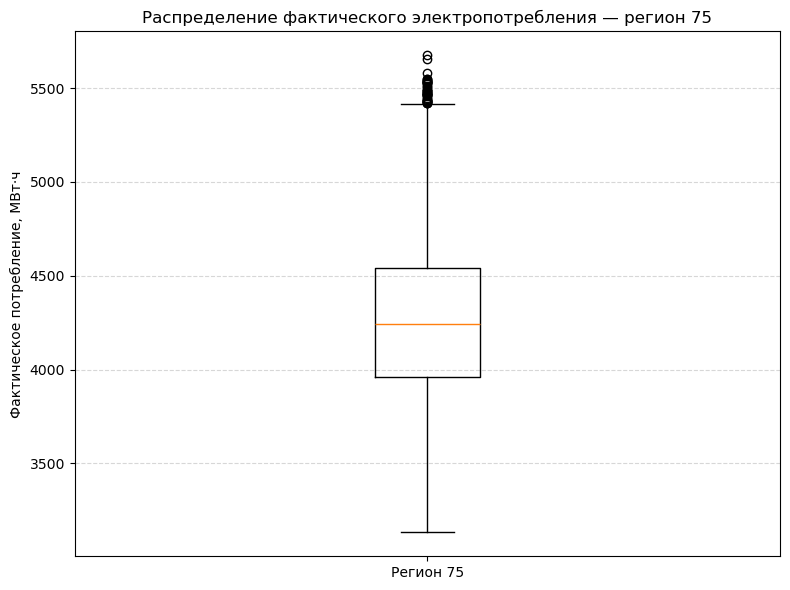

Количество наблюдений: 41537
Медиана: 4241.00 МВт·ч
Минимум: 3132.00 МВт·ч
Максимум: 5675.00 МВт·ч


In [5]:
# Путь к данным
DATA_DIR = "../../../datasets"
FILE_PATH = os.path.join(DATA_DIR, "electricity_75.csv")
TARGET_COLUMN = "actual_consumption"


def parse_consumption(value):
    """Преобразует '4 076 МВт*ч' в число 4076."""
    if pd.isna(value):
        return None

    value = str(value).replace("\xa0", "").replace(" ", "")
    value = value.replace("МВт*ч", "").replace("МВт·ч", "")

    try:
        return float(value.replace(",", "."))
    except ValueError:
        return None


# Загружаем данные региона 75
if not os.path.isfile(FILE_PATH):
    raise FileNotFoundError(
        f"Файл не найден: {os.path.abspath(FILE_PATH)}"
    )

df = pd.read_csv(FILE_PATH, encoding="utf-8-sig")

if TARGET_COLUMN not in df.columns:
    raise ValueError(f"В файле отсутствует столбец {TARGET_COLUMN}")

# Преобразуем потребление в числовой формат
consumption = (
    df[TARGET_COLUMN]
    .apply(parse_consumption)
    .dropna()
)

print(df[TARGET_COLUMN])


if consumption.empty:
    raise ValueError("Нет числовых данных для построения диаграммы.")

# Строим boxplot
plt.figure(figsize=(8, 6))

plt.boxplot(
    consumption,
    tick_labels=["Регион 75"],
    showfliers=True
)

plt.title("Распределение фактического электропотребления — регион 75")
plt.ylabel("Фактическое потребление, МВт·ч")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
#plt.savefig("boxplot_consumption_75.png", dpi=300)
plt.show()

# Выводим основные статистические показатели
print(f"Количество наблюдений: {len(consumption)}")
print(f"Медиана: {consumption.median():.2f} МВт·ч")
print(f"Минимум: {consumption.min():.2f} МВт·ч")
print(f"Максимум: {consumption.max():.2f} МВт·ч")
